# 07 · Escenarios de oferta 2024-2028

- **Base:** promedio ingenuo + LightGBM (detallados) o ingenuo (simplificados), con origen 2023.
- **Bajo / alto:** percentiles 10 y 90 del error logarítmico del walk-forward, por producto y horizonte (≥ 30 observaciones) o por estado y horizonte.
- **Coherencia:** el total departamental es la suma de los municipios (bottom-up).

Archivo contrato para Samuel y Alejandro: `data/results/ML_Ce/oferta_escenarios.csv` (`producto, cod_dane, año, oferta_bajo, oferta_base, oferta_alto`).

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
REENTRENAR = False   # True vuelve a correr 07_escenarios.py (requiere lightgbm)
esc = import_module("07_escenarios")
if REENTRENAR:
    esc.main()
esc.valorizar()
o = pd.read_csv(RES / "oferta_escenarios.csv", dtype={"cod_dane": str})
o.head()

oferta_escenarios_valor.csv: 89% de las filas con precio


,producto,cod_dane,año,oferta_bajo,oferta_base,oferta_alto
0,Aguacate,76001,2024,40.00,72.73,183.87
1,Aguacate,76001,2025,38.04,73.62,295.09
2,Aguacate,76001,2026,35.02,75.21,495.16
3,Aguacate,76001,2027,38.67,75.58,583.71
4,Aguacate,76001,2028,35.70,75.58,742.26


In [3]:
checks = {
    "columnas del contrato": list(o.columns) == ["producto", "cod_dane", "año", "oferta_bajo", "oferta_base", "oferta_alto"],
    "sin nulos": o.notna().all().all(),
    "bajo <= base <= alto": ((o.oferta_bajo <= o.oferta_base) & (o.oferta_base <= o.oferta_alto)).all(),
    "años 2024-2028": sorted(o["año"].unique()) == list(range(2024, 2029)),
    "series": o[["producto", "cod_dane"]].drop_duplicates().shape[0],
    "máx. diferencia municipios vs departamento": pd.read_csv(RES / "coherencia_jerarquica.csv").dif.max(),
}
pd.Series(checks).to_frame("resultado")

,resultado
columnas del contrato,True
sin nulos,True
bajo <= base <= alto,True
años 2024-2028,True
series,724
máx. diferencia municipios vs departamento,0.0


## Cobertura empírica de los intervalos (2019-2023, calibración dejando un origen afuera)

In [4]:
cob = pd.read_csv(RES / "cobertura_intervalos.csv")
cob

,grupo,horizonte,n,cobertura,cobertura_nominal
0,todos,todos,10567,0.759,0.8
1,todos,1,3548,0.764,0.8
2,todos,2,2825,0.762,0.8
3,todos,3,2105,0.760,0.8
4,todos,4,1393,0.737,0.8
5,todos,5,696,0.764,0.8
6,detallado,1,2819,0.768,0.8
7,detallado,2,2247,0.771,0.8
8,detallado,3,1676,0.765,0.8
9,detallado,4,1110,0.740,0.8


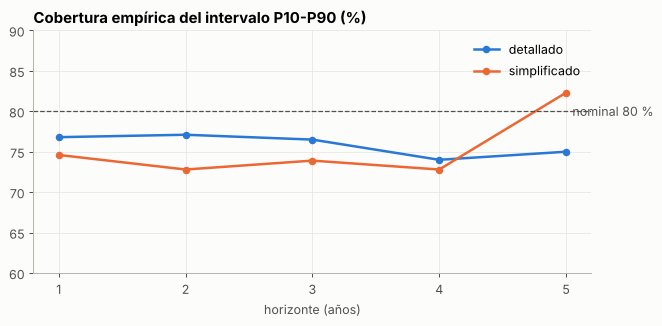

In [5]:
c = cob[(cob.horizonte != "todos")].copy(); c["h"] = c.horizonte.astype(int)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, g in enumerate(["detallado", "simplificado"]):
    s = c[c.grupo == g]; ax.plot(s.h, s.cobertura * 100, marker="o", ms=5, color=COLORES[i], label=g)
ax.axhline(80, color="#52514e", ls="--", lw=1); ax.text(5.05, 80, "nominal 80 %", va="center", color="#52514e")
ax.set_ylim(60, 90); ax.set_xticks(range(1, 6)); ax.set_xlabel("horizonte (años)"); ax.set_title("Cobertura empírica del intervalo P10-P90 (%)"); ax.legend()
plt.show()

La cobertura total es **75,9 %** frente al 80 % nominal: los intervalos son algo angostos y no deben presentarse como perfectamente calibrados.

## Oferta departamental por producto

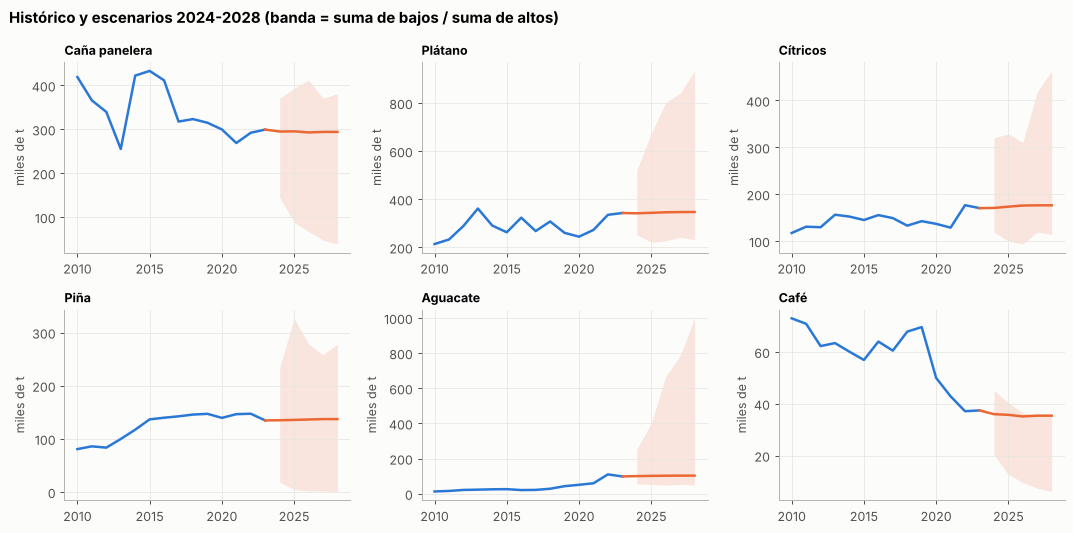

In [6]:
hist = pd.read_csv(CLEAN / "produccion_valle_clean.csv").groupby(["producto", "anio"])["produccion_t"].sum()
dep = pd.read_csv(RES / "oferta_departamento.csv")
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, p in zip(axs.flat, ["Caña panelera", "Plátano", "Cítricos", "Piña", "Aguacate", "Café"]):
    h = hist.loc[p].loc[2010:] / 1e3; f = dep[dep.producto == p].set_index("año")[["oferta_bajo", "oferta_base", "oferta_alto"]] / 1e3
    ax.plot(h.index, h.values, color=COLORES[0])
    ax.plot([2023] + list(f.index), [h.iloc[-1]] + list(f.oferta_base), color=COLORES[1])
    ax.fill_between(f.index, f.oferta_bajo, f.oferta_alto, color=COLORES[1], alpha=0.15, lw=0)
    ax.set_title(p, fontsize=10); ax.set_ylabel("miles de t")
fig.suptitle("Histórico y escenarios 2024-2028 (banda = suma de bajos / suma de altos)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

La banda departamental suma los extremos municipales: describe el caso en que **todos** los municipios caen o suben a la vez, así que es más ancha que el rango real del departamento.

## Oferta valorizada (para ponderar zonas por valor)

In [7]:
ov = pd.read_csv(RES / "oferta_escenarios_valor.csv", dtype={"cod_dane": str})
(ov[ov["año"] == 2024].groupby("producto")[["valor_bajo_cop", "valor_base_cop", "valor_alto_cop"]].sum() / 1e9).round(1).sort_values("valor_base_cop", ascending=False).head(12).rename(columns=lambda c: c.replace("_cop", " (miles de millones COP)"))

,valor_bajo (miles de millones COP),valor_base (miles de millones COP),valor_alto (miles de millones COP)
producto,,,
Caña de azúcar,9024.5,10195.9,12438.5
Plátano,477.1,643.5,980.7
Café,325.5,573.8,720.6
Aguacate,284.7,512.1,1284.3
Cítricos,283.4,406.0,762.5
Piña,33.1,243.0,420.4
Caña panelera,61.3,124.4,156.3
Banano,71.2,124.4,202.8
Vid,72.7,113.0,183.5
